## COMP90049 Victorian Road Accident Research
### Data Processing Module
Authored by Stephen Zhang - Human Learning Machines

### Prerequisites:
- Numpy
- Pandas
- Matplotlib
- Pyarrow (if you wish to produce the final parquet for further processing)

### Data:
#### Raw data from Transport Victoria: `data/raw/`
These files will be processed by this notebook directly
- `accident.csv`: Main table of accidents
- `accident_location.csv`: Location information of accidents
- `node.csv`: Node (intersection) information of accidents
#### Pre-processed data: `data/`
These files were pre-processed with one-hot encoding by different team members
- `atmospheric_cond_rq1.csv`: Weather conditions of accidents
- `road_surface_cond_rq1.csv`: Road surface conditions of accidents
- `vehicle_rq1.csv`: Vehicles and driving status of accidents

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from functools import reduce
import pyarrow

In [31]:
plt.style.use("tableau-colorblind10")
import matplotlib as mpl
from matplotlib import font_manager
available_fonts = {f.name for f in font_manager.fontManager.ttflist}
if ("IBM Plex Mono" in available_fonts):
    mpl.rcParams.update({
        "font.family": "sans-serif",
        "font.sans-serif": ["IBM Plex Mono"],
        "font.monospace": ["IBM Plex Mono"],
        "axes.unicode_minus": False,
        "font.size": 12,
        "figure.dpi": 120,
    })

### Global vars

In [33]:
RAW_DATA_DIR = "data/raw/"
DATA_DIR = "data/"
RQ1_DATA_DIR = "data/rq1/"

ACC_RAW = RAW_DATA_DIR + "accident.csv"
ACC_LOC_RAW = RAW_DATA_DIR + "accident_location.csv"
NODE_RAW = RAW_DATA_DIR + "node.csv"

ATMO_COND_ONEHOT = DATA_DIR + "atmospheric_cond_rq1.csv"
ROAD_SURF_COND_ONEHOT = DATA_DIR + "road_surface_cond_rq1.csv"
VEH_ONEHOT = DATA_DIR + "vehicle_rq1.csv"

### Data integrity check
Files to be checked:
- `raw/accident.csv`: 195617 rows, last entry `ACCIDENT_NO = T20240009130`
- `raw/accident_location.csv`: 195617 rows, last entry `ACCIDENT_NO = T20170024820`
- `raw/node.csv`: 198608 rows, last entry `ACCIDENT_NO = T20250012944`
- `atmospheric_cond_rq1.csv`: 195617 rows, last entry `ACCIDENT_NO = T20260003651`
- `road_surface_cond_rq1.csv`: 195617 rows, last entry `ACCIDENT_NO = T20260003651`
- `vehicle_rq1.csv`: 195608 rows, last entry `ACCIDENT_NO = T20260003651`

Note: these files were fetched on 10/05/2026.

In [35]:
import hashlib

def file_hash(path, algorithm="sha256"):
    h = hashlib.new(algorithm)
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(8192), b""):
            h.update(chunk)
    return h.hexdigest()

# RAW data
assert(file_hash(ACC_RAW) == "689d2ce41f1ace8fa72bad7bd522e4c5fd4ad5dc3c1dc134055a951e0c9727c4")
assert(file_hash(ACC_LOC_RAW) == "319e727f368c590a4bb40e4598a4394e224d0ce685b47cd342a6dd3e0fa0d12f")
assert(file_hash(NODE_RAW) == "f2dd1fd9f7e7a725e5a89ef405f29db69c2357e07ef3faac1b8e01213e7b1c0f")

# Pre-processed data
assert(file_hash(ATMO_COND_ONEHOT) == "1be008f4b8979b1bb950ed67f683ad46860a2256eeb72c7d14577d96459073d9")
assert(file_hash(ROAD_SURF_COND_ONEHOT) == "8035405d99e7e09f4f515e53d99797848d6b3fabf043ca7c9ed18056d3e8fee8")
assert(file_hash(VEH_ONEHOT) == "01158f8cb5ead316e44f1a2cd15f2393bfaf7906a02ea5f0ae03b4bdd920e463")


### Select attributes for use of RQ1
Read from RAW_DATA_DIR and output into DATA_DIR

This will produce `accident_rq1.csv`, `node_rq1.csv`, and `accident_location_rq1.csv`.

In [ ]:
def select_attrs():
    ACCIDENTS_ATTRS = ["ACCIDENT_NO","ACCIDENT_DATE","ACCIDENT_TIME",
    "ACCIDENT_TYPE","DCA_CODE","LIGHT_CONDITION",
    "NODE_ID","NO_OF_VEHICLES","ROAD_GEOMETRY",
    "SEVERITY","SPEED_ZONE","RMA"]

    NODE_ATTRS = ["ACCIDENT_NO","NODE_TYPE","DEG_URBAN_NAME"]

    ACCIDENT_LOCATION_ATTRS = ["ACCIDENT_NO", "ROAD_TYPE", "ROAD_TYPE_INT"]

    df = pd.read_csv(RAW_DATA_DIR + "accident.csv")
    filtered_df = df[ACCIDENTS_ATTRS]
    filtered_df.to_csv(DATA_DIR + "accident_rq1.csv", index=False)
    n, m = df.shape
    print(f"accident {n} x {m}")

    df = pd.read_csv(RAW_DATA_DIR + "node.csv")
    filtered_df = df[NODE_ATTRS]
    filtered_df.to_csv(DATA_DIR + "node_rq1.csv", index=False)
    n, m = df.shape
    print(f"node {n} x {m}")

    df = pd.read_csv(RAW_DATA_DIR + "accident_location.csv")
    filtered_df = df[ACCIDENT_LOCATION_ATTRS]
    filtered_df.to_csv(DATA_DIR + "accident_location_rq1.csv", index=False)
    n, m = df.shape
    print(f"accident_location {n} x {m}")

select_attrs()

### Deduplicate `node_rq1.csv`
Make multiples of `DEG_URBAN_NAME` into one single val `MIXED`

This will produce `node_rq1_dedup.csv`

In [ ]:
def dup_to_mixed(series):
    v = series.dropna().unique()

    if (len(v) == 0):
        return pd.NA
    if (len(v) == 1):
        return v[0]
    return "MIXED"

def dedup_node():
    df = pd.read_csv(DATA_DIR + "node_rq1.csv")
    converted = (
        df.groupby("ACCIDENT_NO", as_index=False).agg({
            "NODE_TYPE": dup_to_mixed,
            "DEG_URBAN_NAME": dup_to_mixed
        })
    )
    converted.to_csv(DATA_DIR + "node_rq1_dedup.csv", index=False)
    print(converted.shape)

dedup_node()

### Sorting preamble

In [ ]:
def parse_accident_no(accident_no):
        """
        Year is likely report year, not accident year
        T20120004011 -> (2012, 4011)
        """
        match = re.match(r"^T(\d{4})(\d{7})$", accident_no)
        if not match:
            return (9999, float("inf"))
        year = int(match.group(1))
        number = int(match.group(2))
        return (year, number)

def sort_accident_no(values):
    return sorted(values, key=parse_accident_no)

### Check distribution of missing accidents for each files

accident_rq1.csv          :  195617 rows,  195617 unique ACCIDENT_NO
atmospheric_cond_rq1.csv  :  195617 rows,  195617 unique,       0 missing,       0 extra, max  T20260003651, min  T20120000009 ACCIDENT_NO
road_surface_cond_rq1.csv :  195617 rows,  195617 unique,       0 missing,       0 extra, max  T20260003651, min  T20120000009 ACCIDENT_NO
vehicle_rq1.csv           :  195608 rows,  195608 unique,       9 missing,       0 extra, max  T20260003651, min  T20120000009 ACCIDENT_NO
accident_location_rq1.csv :  195617 rows,  195617 unique,       0 missing,       0 extra, max  T20260003651, min  T20120000009 ACCIDENT_NO
node_rq1_dedup.csv        :  195532 rows,  195532 unique,      85 missing,       0 extra, max  T20260003651, min  T20120000009 ACCIDENT_NO
Common ACCIDENT_NO: 195523

Missing ACCIDENT_NO:
vehicle_rq1.csv           : T20230030888 T20190002653 T20210022607 T20230027118 T20210022263 T20220002330 T20200008868 T20200012731 T20230009098
node_rq1_dedup.csv        : T20210009023 T

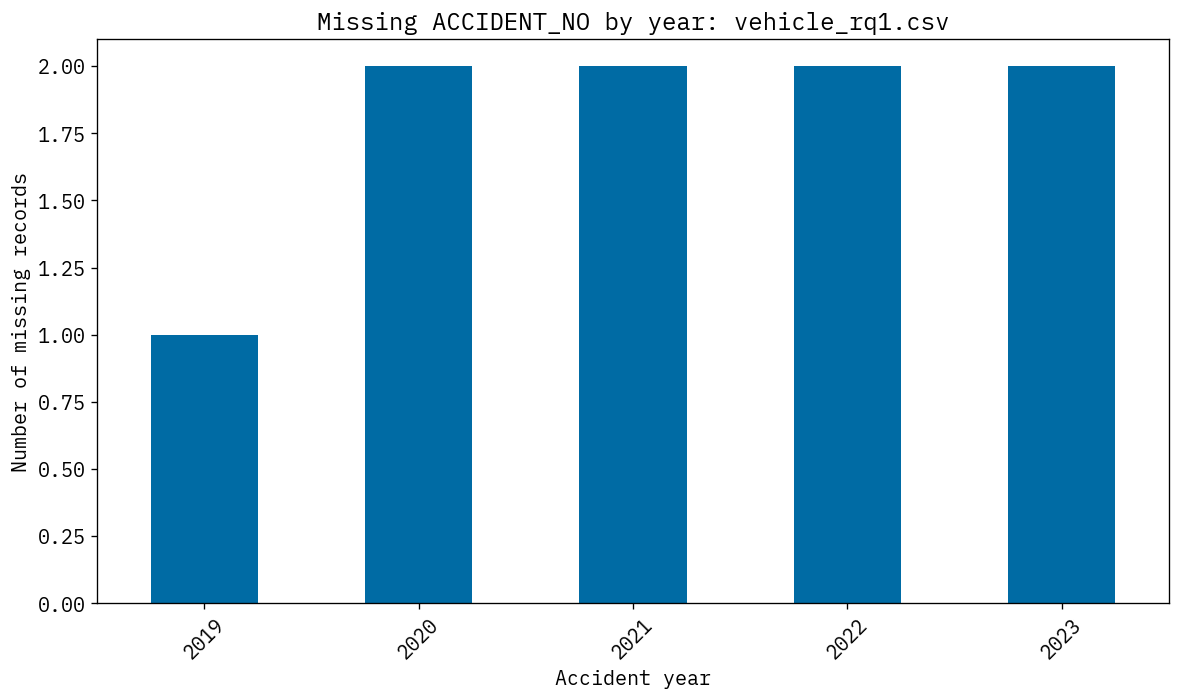


node_rq1_dedup.csv
ACCIDENT_YEAR
2012    31
2013     6
2016     5
2017     7
2018    13
2019    16
2020     1
2021     4
2022     2
Name: count, dtype: int64


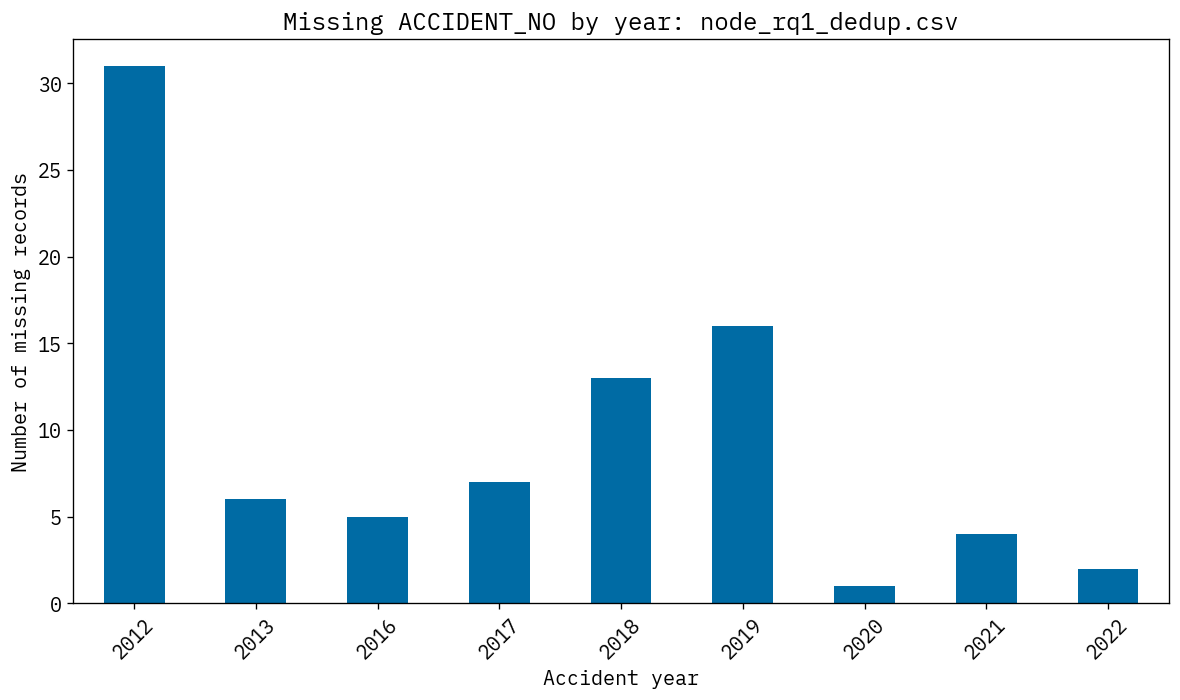

In [ ]:
def print_stats():
    files = [
        "atmospheric_cond_rq1.csv",
        "road_surface_cond_rq1.csv",
        "vehicle_rq1.csv",
        "accident_location_rq1.csv",
        "node_rq1_dedup.csv",
    ]

    accident_df = pd.read_csv(DATA_DIR + "accident_rq1.csv")
    base_accident_set = set(accident_df["ACCIDENT_NO"].dropna())
    print(f"accident_rq1.csv          : {accident_df.shape[0]:>7} rows, {len(base_accident_set):>7} unique ACCIDENT_NO")

    sets = [base_accident_set]
    missings = {}
    extras = {}
    for file in files:
        df = pd.read_csv(DATA_DIR + file)
        accident_set = set(df["ACCIDENT_NO"].dropna())
        missing_rows = base_accident_set - accident_set
        extra_rows = accident_set - base_accident_set
        missings[file] = missing_rows
        extras[file] = extra_rows
        sorted_accident_set = sort_accident_no(accident_set)

        print(f"{file:<26}: {df.shape[0]:>7} rows, {len(accident_set):>7} unique," + 
            f" {len(missing_rows):>7} missing, {len(extra_rows):>7} extra, max {sorted_accident_set[-1]:>13}, min {sorted_accident_set[0]:>13} ACCIDENT_NO")
        sets.append(accident_set)
    common_accident_no = set.intersection(*sets)
    print(f"Common ACCIDENT_NO: {len(common_accident_no)}")
    print()
    print("Missing ACCIDENT_NO:")
    for k, v in missings.items():
        k: str
        v: set
        if (len(v) == 0): continue
        print(f"{k:<26}: {" ".join(v)}")

    print()
    print("Extra ACCIDENT_NO:")
    for k, v in extras.items():
        k: str
        v: set
        if (len(v) == 0): continue
        print(f"{k:<26}: {" ".join(v)}")

    # Prepare plot
    accident_df["ACCIDENT_DATE"] = pd.to_datetime(
        accident_df["ACCIDENT_DATE"].astype(str).str.strip(),
        format="%Y-%m-%d",
        errors="coerce"
    )
    accident_df["ACCIDENT_YEAR"] = accident_df["ACCIDENT_DATE"].dt.year
    for file, missing_set in missings.items():
        file: str
        missing_set: set
        if (len(missing_set) == 0): continue
        missing_df = pd.DataFrame({
            "ACCIDENT_NO": sorted(missing_set)
        })

        missing_df = missing_df.merge(
            accident_df[["ACCIDENT_NO", "ACCIDENT_DATE", "ACCIDENT_YEAR"]],
            on="ACCIDENT_NO",
            how="left"
        )

        table = (
            missing_df["ACCIDENT_YEAR"]
            .value_counts(dropna=False)
            .sort_index()
        )

        table.columns = ["ACCIDENT_YEAR", "MISSING_COUNT"]
        print(f"\n{file}")
        print(table)
        plt.figure(figsize=(10, 6))
        table.plot(kind="bar")

        plt.xlabel("Accident year")
        plt.ylabel("Number of missing records")
        plt.title(f"Missing ACCIDENT_NO by year: {file}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig(f"missing_by_year_{file}.png", dpi=300)
        plt.show()

print_stats()

### Data merge (into one df)

In [ ]:
ACC_RQ1_IN = DATA_DIR + "accident_rq1.csv"
ACC_LOC_RQ1_IN = DATA_DIR + "accident_location_rq1.csv"
NODE_RQ1_IN = DATA_DIR + "node_rq1_dedup.csv"

files = [ACC_RQ1_IN, ACC_LOC_RQ1_IN, NODE_RQ1_IN, ATMO_COND_ONEHOT, ROAD_SURF_COND_ONEHOT, VEH_ONEHOT]

dfs = {}
for file in files:
    df = pd.read_csv(file)
    df.columns = df.columns.str.strip()
    dfs[file] = df

common_ids = set.intersection(*[
    set(df["ACCIDENT_NO"].dropna())
    for df in dfs.values()
])

print(f"Common ACCIDENT_NO: {len(common_ids)}")

# Data check
assert(len(common_ids) == 195523)

for file in files:
    dfs[file] = dfs[file][dfs[file]["ACCIDENT_NO"].isin(common_ids)].copy()
    assert(dfs[file].shape[0] == 195523)

Common ACCIDENT_NO: 195523


In [ ]:
# Join tables
merged_df = reduce(
    lambda l, r: pd.merge(l, r, on="ACCIDENT_NO", how="inner"),
    dfs.values()
)

print(f"Merged dataset: {merged_df.shape}")

with pd.option_context("display.max_rows", None):
    print(merged_df.dtypes)

Merged dataset: (195523, 97)
ACCIDENT_NO                                                          str
ACCIDENT_DATE                                                        str
ACCIDENT_TIME                                                        str
ACCIDENT_TYPE                                                      int64
DCA_CODE                                                           int64
LIGHT_CONDITION                                                    int64
NODE_ID                                                            int64
NO_OF_VEHICLES                                                     int64
ROAD_GEOMETRY                                                      int64
SEVERITY                                                           int64
SPEED_ZONE                                                         int64
RMA                                                                  str
ROAD_TYPE                                                            str
ROAD_TYPE_INT         

### Feature engineering

In [ ]:
# Convert date time
merged_df["ACCIDENT_DATE"] = pd.to_datetime(
    merged_df["ACCIDENT_DATE"].astype(str).str.strip(),
    format="%Y-%m-%d",
    errors="coerce"
)

merged_df["ACCIDENT_YEAR"] = merged_df["ACCIDENT_DATE"].dt.year
merged_df["ACCIDENT_MONTH"] = merged_df["ACCIDENT_DATE"].dt.month
merged_df["ACCIDENT_HOUR"] = pd.to_datetime(
    merged_df["ACCIDENT_TIME"].astype(str).str.strip(),
    format="%H:%M:%S",
    errors="coerce"
).dt.hour
df = merged_df.drop(columns=["ACCIDENT_DATE", "ACCIDENT_TIME"])

# Convert categorical type
cat_cols = [
    "ACCIDENT_TYPE",
    "DCA_CODE",
    "LIGHT_CONDITION",
    "ROAD_GEOMETRY",
    "RMA",
    "ROAD_TYPE",
    "ROAD_TYPE_INT",
    "NODE_TYPE",
    "DEG_URBAN_NAME",
]
for col in cat_cols:
    df[col] = df[col].astype("category")

# Reduce one-hot cols into int8 to save memory
one_hot_cols = [col for col in df.columns if col.startswith(("atmos_", "surface_", "vehicle_", "intent_", "traffic_control_"))]
for col in one_hot_cols:
    df[col] = df[col].astype("int8")

# Check data types
with pd.option_context("display.max_rows", None):
    print(df.dtypes)

ACCIDENT_NO                                                             str
ACCIDENT_TYPE                                                      category
DCA_CODE                                                           category
LIGHT_CONDITION                                                    category
NODE_ID                                                               int64
NO_OF_VEHICLES                                                        int64
ROAD_GEOMETRY                                                      category
SEVERITY                                                              int64
SPEED_ZONE                                                            int64
RMA                                                                category
ROAD_TYPE                                                          category
ROAD_TYPE_INT                                                      category
NODE_TYPE                                                          category
DEG_URBAN_NA

### Data sanitisation

In [ ]:
# Check speed zone values

print(df["SPEED_ZONE"].value_counts(dropna=False).sort_index())

# Replace special speed zone with NA for numerical processing
df["SPEED_ZONE"] = df["SPEED_ZONE"].replace({
    777: pd.NA,
    888: pd.NA,
    999: pd.NA
})

print(df["SPEED_ZONE"].value_counts(dropna=False).sort_index())

SPEED_ZONE
30       400
40     12611
50     32208
60     63885
70     12298
75        20
80     29573
90       500
100    27533
110     2019
777      370
888     1289
999    12817
Name: count, dtype: int64
SPEED_ZONE
30        400
40      12611
50      32208
60      63885
70      12298
75         20
80      29573
90        500
100     27533
110      2019
<NA>    14476
Name: count, dtype: int64


### Save for RQ1

In [ ]:
df.to_parquet("rq1.parquet", index=False)

### Next step: rq1.ipynb